# Initial enthalpy calculations and enthalpy modelling

Experimentally, the enthalpy of adsorption can be obtained either indirectly,
through the isosteric enthalpy method, or directly, using adsorption
microcalorimetry. Once an enthalpy curve is calculated, a useful performance
indicator is the enthalpy of adsorption at zero loading, corresponding to the
initial interactions of the probe with the surface. pyGAPS contains two methods
to determine the initial enthalpy of adsorption starting from an enthalpy curve.

First, make sure the data is imported by running the import notebook.

In [1]:
# import isotherms
%run import.ipynb

# import the characterisation module
import pygaps.characterisation as pgc

Selected 5 isotherms with nitrogen at 77K
Selected 2 room temperature calorimetry isotherms
Selected 2 isotherms for IAST calculation
Selected 3 isotherms for isosteric enthalpy calculation


### Initial point method

The point method of determining enthalpy of adsorption is the simplest method.
It just returns the first measured point in the enthalpy curve.

Depending on the data, the first point method may or may not be representative
of the actual value.

The initial enthalpy of adsorption is: 
	E = 28.8


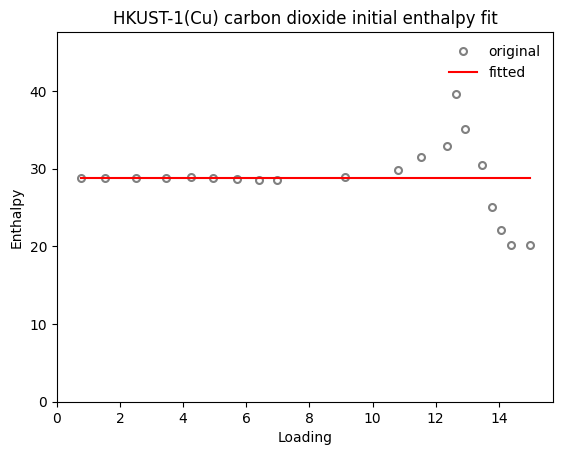

The initial enthalpy of adsorption is: 
	E = 34.7


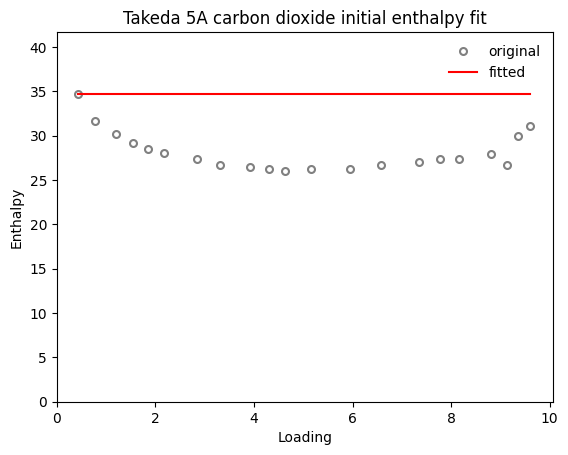

In [2]:
import matplotlib.pyplot as plt

# Initial point method
isotherm = next(i for i in isotherms_calorimetry if i.material == 'HKUST-1(Cu)')
res = pgc.initial_enthalpy_point(isotherm, 'enthalpy', verbose=True)
plt.show()

isotherm = next(i for i in isotherms_calorimetry if i.material == 'Takeda 5A')
res = pgc.initial_enthalpy_point(isotherm, 'enthalpy', verbose=True)
plt.show()


### Compound model method

This method attempts to model the enthalpy curve by the superposition of several
contributions. It is slower, as it runs a constrained minimisation algorithm
with several initial starting guesses, then selects the optimal one.

Bounds: 
	const = (np.float64(19.849417219261177), np.float64(37.63022921697883))


	preexp = (0, 150), exp = (0, inf), exploc = (0, 0.5)


	prepowa = (0, 50), powa = (1, 20)


	prepowr = (-50, 0), powr = (1, 20)


Minimizing routine number 1


Initial guess: 
	const = 28.739823218120005


... (26 outputs left out)

The constant contribution is 
	19.8


The exponential contribution is 
	8.71 * exp(15.1 * n)with the limit at 0.407


The guest-guest attractive contribution is 
	47.7 * n^2.59


The guest-guest repulsive contribution is 
	-50 * n^5.48


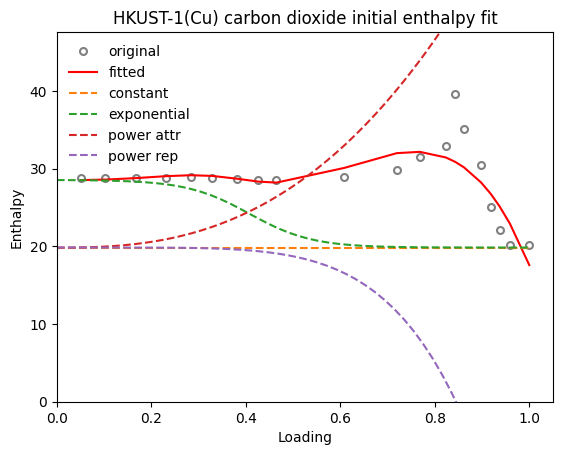

Bounds: 
	const = (np.float64(23.797607891739087), np.float64(32.54769036367995))


	preexp = (0, 150), exp = (0, inf), exploc = (0, 0.5)


	prepowa = (0, 50), powa = (1, 20)


	prepowr = (-50, 0), powr = (1, 20)


Minimizing routine number 1


Initial guess: 
	const = 28.17264912770952


... (26 outputs left out)

The constant contribution is 
	26.5


The exponential contribution is 
	21.2 * exp(12.3 * n)with the limit at 1.14e-17


The guest-guest attractive contribution is 
	50 * n^18.1


The guest-guest repulsive contribution is 
	-45.6 * n^18.1


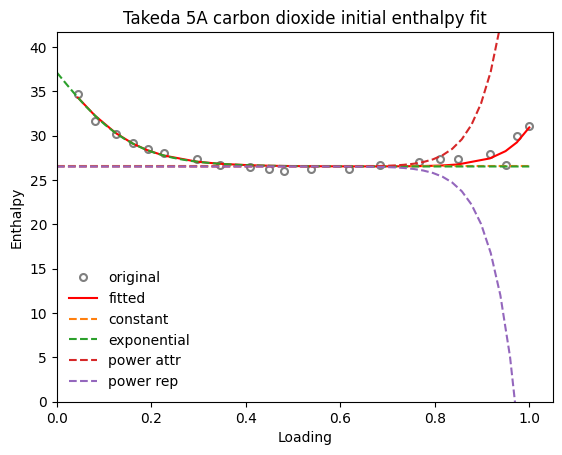

In [3]:
# Modelling method
isotherm = next(i for i in isotherms_calorimetry if i.material == 'HKUST-1(Cu)')
res = pgc.initial_enthalpy_comp(isotherm, 'enthalpy', verbose=True)
plt.show()

isotherm = next(i for i in isotherms_calorimetry if i.material == 'Takeda 5A')
res = pgc.initial_enthalpy_comp(isotherm, 'enthalpy', verbose=True)
plt.show()